# 01. Tìm hiểu dữ liệu tài chính

Notebook này khảo sát cấu trúc, chất lượng sơ bộ và phân phối của bộ dữ liệu khách hàng trước khi làm sạch hoặc xây dựng mô hình. Đường dẫn dữ liệu được lấy từ `configs/config.yaml`.

Theo [từ điển dữ liệu](../docs/finance_dictionary.md), dữ liệu mô phỏng hồ sơ khách hàng ngân hàng, gồm thông tin nhân khẩu học, việc làm, hành vi tín dụng, tài khoản và đầu tư. Hai biến mục tiêu là `credit_risk` (phân loại 4 mức) và `fraud_risk_score` (điểm số liên tục). Từ điển cũng lưu ý dữ liệu có giá trị thiếu, ngoại lệ và lỗi nhập liệu có chủ đích; notebook này chỉ nhận diện sơ bộ, chưa sửa dữ liệu.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import yaml

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")
sns.set_theme(style="whitegrid", palette="muted")

# Tìm config từ thư mục làm việc hiện tại hoặc các thư mục cha.
working_directory = Path.cwd().resolve()
project_root = next(
    (path for path in (working_directory, *working_directory.parents)
     if (path / "configs" / "config.yaml").is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError("Không tìm thấy configs/config.yaml từ thư mục làm việc hiện tại.")

config_path = project_root / "configs" / "config.yaml"
with config_path.open(encoding="utf-8") as config_file:
    config = yaml.safe_load(config_file)

raw_data_path = project_root / config["data"]["raw_path"]
if not raw_data_path.is_file():
    raise FileNotFoundError(f"Không tìm thấy dữ liệu raw theo config: {raw_data_path}")

classification_target = config["targets"]["classification"]
regression_target = config["targets"]["regression"]
df = pd.read_csv(raw_data_path)

print(f"Config: {config_path}")
print(f"Dữ liệu: {raw_data_path}")
print(f"Kích thước: {df.shape[0]:,} dòng x {df.shape[1]} cột")
display(df.head())

Config: E:\Personal Project\Data science_analyze finance\configs\config.yaml
Dữ liệu: E:\Personal Project\Data science_analyze finance\data\raw\synthetic_finance_20250901.csv
Kích thước: 750,000 dòng x 23 cột


,customer_id,age,income,credit_score,employment_years,employment_status,education_level,marital_status,home_ownership,region,account_age_months,monthly_spending,credit_utilization,num_credit_cards,num_loans,late_payment_months,debt_to_income,savings_rate,investment_value,account_creation_date,last_transaction_date,credit_risk,fraud_risk_score
0,FN0000001,61,"33,027.320",748,3.100,Self-employed,Some College,Single,Mortgage,West,33,80.000,0.388,2,2,1,0.030,0.369,"7,404.550",2023-04-07,2024-12-12,0,0.610
1,FN0000002,39,"42,965.710",661,4.400,Self-employed,Some College,Single,Mortgage,West,32,674.900,0.435,2,1,4,0.188,0.281,"9,356.300",2022-04-30,2024-12-21,0,0.386
2,FN0000003,53,"22,000.000",547,82.000,Part-time,High School,Single,Rent,Northeast,14,976.700,0.295,2,3,2,0.533,0.232,"7,525.190",2022-11-18,2024-12-18,2,0.446
3,FN0000004,37,"43,531.060",727,3.600,Self-employed,Some College,Single,Mortgage,Midwest,11,80.000,0.261,1,0,1,0.030,0.257,"20,811.100",2021-05-27,2024-12-26,0,0.424
4,FN0000005,41,"22,956.160",636,3.700,Part-time,Some College,Married,Rent,Southeast,11,555.690,0.484,3,0,3,0.290,0.248,"2,863.830",2024-02-15,2024-12-19,1,0.443


## 1. Kích thước, cấu trúc và kiểu dữ liệu

Đối chiếu tên cột thực tế với từ điển, kiểm tra kiểu dữ liệu được pandas suy luận và mức sử dụng bộ nhớ. Các cột ngày đang được đọc ban đầu dưới dạng chuỗi để giữ nguyên dữ liệu gốc; chúng sẽ được phân tích riêng ở phần thời gian.

In [ ]:
expected_columns = {
    "customer_id", "age", "income", "credit_score", "employment_years",
    "employment_status", "education_level", "marital_status", "home_ownership",
    "region", "account_age_months", "monthly_spending", "credit_utilization",
    "num_credit_cards", "num_loans", "late_payment_months", "debt_to_income",
    "savings_rate", "investment_value", "account_creation_date",
    "last_transaction_date", classification_target, regression_target,
}
actual_columns = set(df.columns)

print("Số dòng:", f"{len(df):,}")
print("Số cột:", len(df.columns))
print("Bộ nhớ DataFrame:", f"{df.memory_usage(deep=True).sum() / 1024**2:,.1f} MB")
print("Cột thiếu so với từ điển:", sorted(expected_columns - actual_columns))
print("Cột ngoài từ điển:", sorted(actual_columns - expected_columns))

display(
pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "non_null": df.notna().sum(),
    "unique_values": df.nunique(dropna=True),
}).rename_axis("column")
)

## 2. Chất lượng sơ bộ và định danh

Thống kê giá trị thiếu theo cột, số dòng trùng lặp hoàn toàn và số `customer_id` bị lặp. Đây là tín hiệu để định hướng kiểm tra sâu ở notebook chất lượng dữ liệu; không loại bỏ hay điền bất kỳ bản ghi nào tại đây.

Số dòng trùng hoàn toàn: 0
Số customer_id trùng: 0
Số cột có dữ liệu thiếu: 6


,missing_count,missing_percent
savings_rate,5766,0.77%
monthly_spending,5227,0.70%
credit_utilization,5222,0.70%
debt_to_income,5182,0.69%
investment_value,568,0.08%
income,530,0.07%


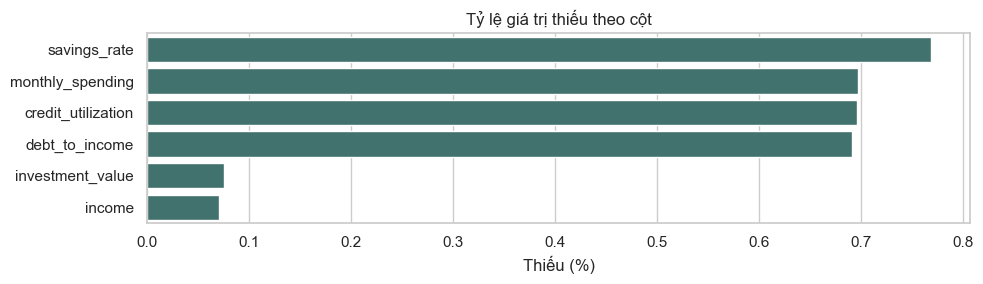

In [2]:
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": df.isna().mean().mul(100),
}).query("missing_count > 0").sort_values("missing_percent", ascending=False)

duplicate_rows = int(df.duplicated().sum())
duplicate_customer_ids = int(df["customer_id"].duplicated().sum()) if "customer_id" in df else None

print("Số dòng trùng hoàn toàn:", f"{duplicate_rows:,}")
print("Số customer_id trùng:", f"{duplicate_customer_ids:,}" if duplicate_customer_ids is not None else "Không có cột customer_id")
print("Số cột có dữ liệu thiếu:", len(missing_summary))
if missing_summary.empty:
    print("Không phát hiện giá trị thiếu.")
else:
    display(missing_summary.style.format({"missing_percent": "{:.2f}%"}))

if not missing_summary.empty:
    fig, ax = plt.subplots(figsize=(10, max(3, 0.35 * len(missing_summary))))
    sns.barplot(data=missing_summary.reset_index(names="column"), x="missing_percent", y="column", ax=ax, color="#397a73")
    ax.set(title="Tỷ lệ giá trị thiếu theo cột", xlabel="Thiếu (%)", ylabel="")
    plt.tight_layout()
    plt.show()

## 3. Các biến số

Xem thống kê mô tả và hình dạng phân phối của các biến số đầu vào. Các biểu đồ chỉ phục vụ nhận diện độ lệch và giá trị bất thường; quyết định xử lý cần được thực hiện ở các bước sau.

,count,mean,std,min,25%,50%,75%,max
age,"750,000.000",43.744,14.561,18.000,33.000,43.000,54.000,88.000
income,"749,470.000","45,409.078","84,784.170","22,000.000","24,860.930","36,301.585","53,092.853","4,977,921.366"
credit_score,"750,000.000",677.536,93.798,30.000,615.000,679.000,744.000,850.000
employment_years,"750,000.000",6.431,9.863,0.300,3.100,4.500,6.700,99.000
account_age_months,"750,000.000",23.000,14.241,1.000,13.000,20.000,29.000,300.000
monthly_spending,"744,773.000",685.526,"4,453.955",80.000,85.100,474.120,874.540,"249,969.372"
credit_utilization,"744,778.000",0.389,0.150,0.019,0.276,0.378,0.493,0.946
num_credit_cards,"750,000.000",3.493,5.427,1.000,2.000,3.000,4.000,59.000
num_loans,"750,000.000",1.880,1.451,0.000,1.000,2.000,3.000,10.000
late_payment_months,"750,000.000",2.629,9.096,0.000,0.000,1.000,2.000,99.000


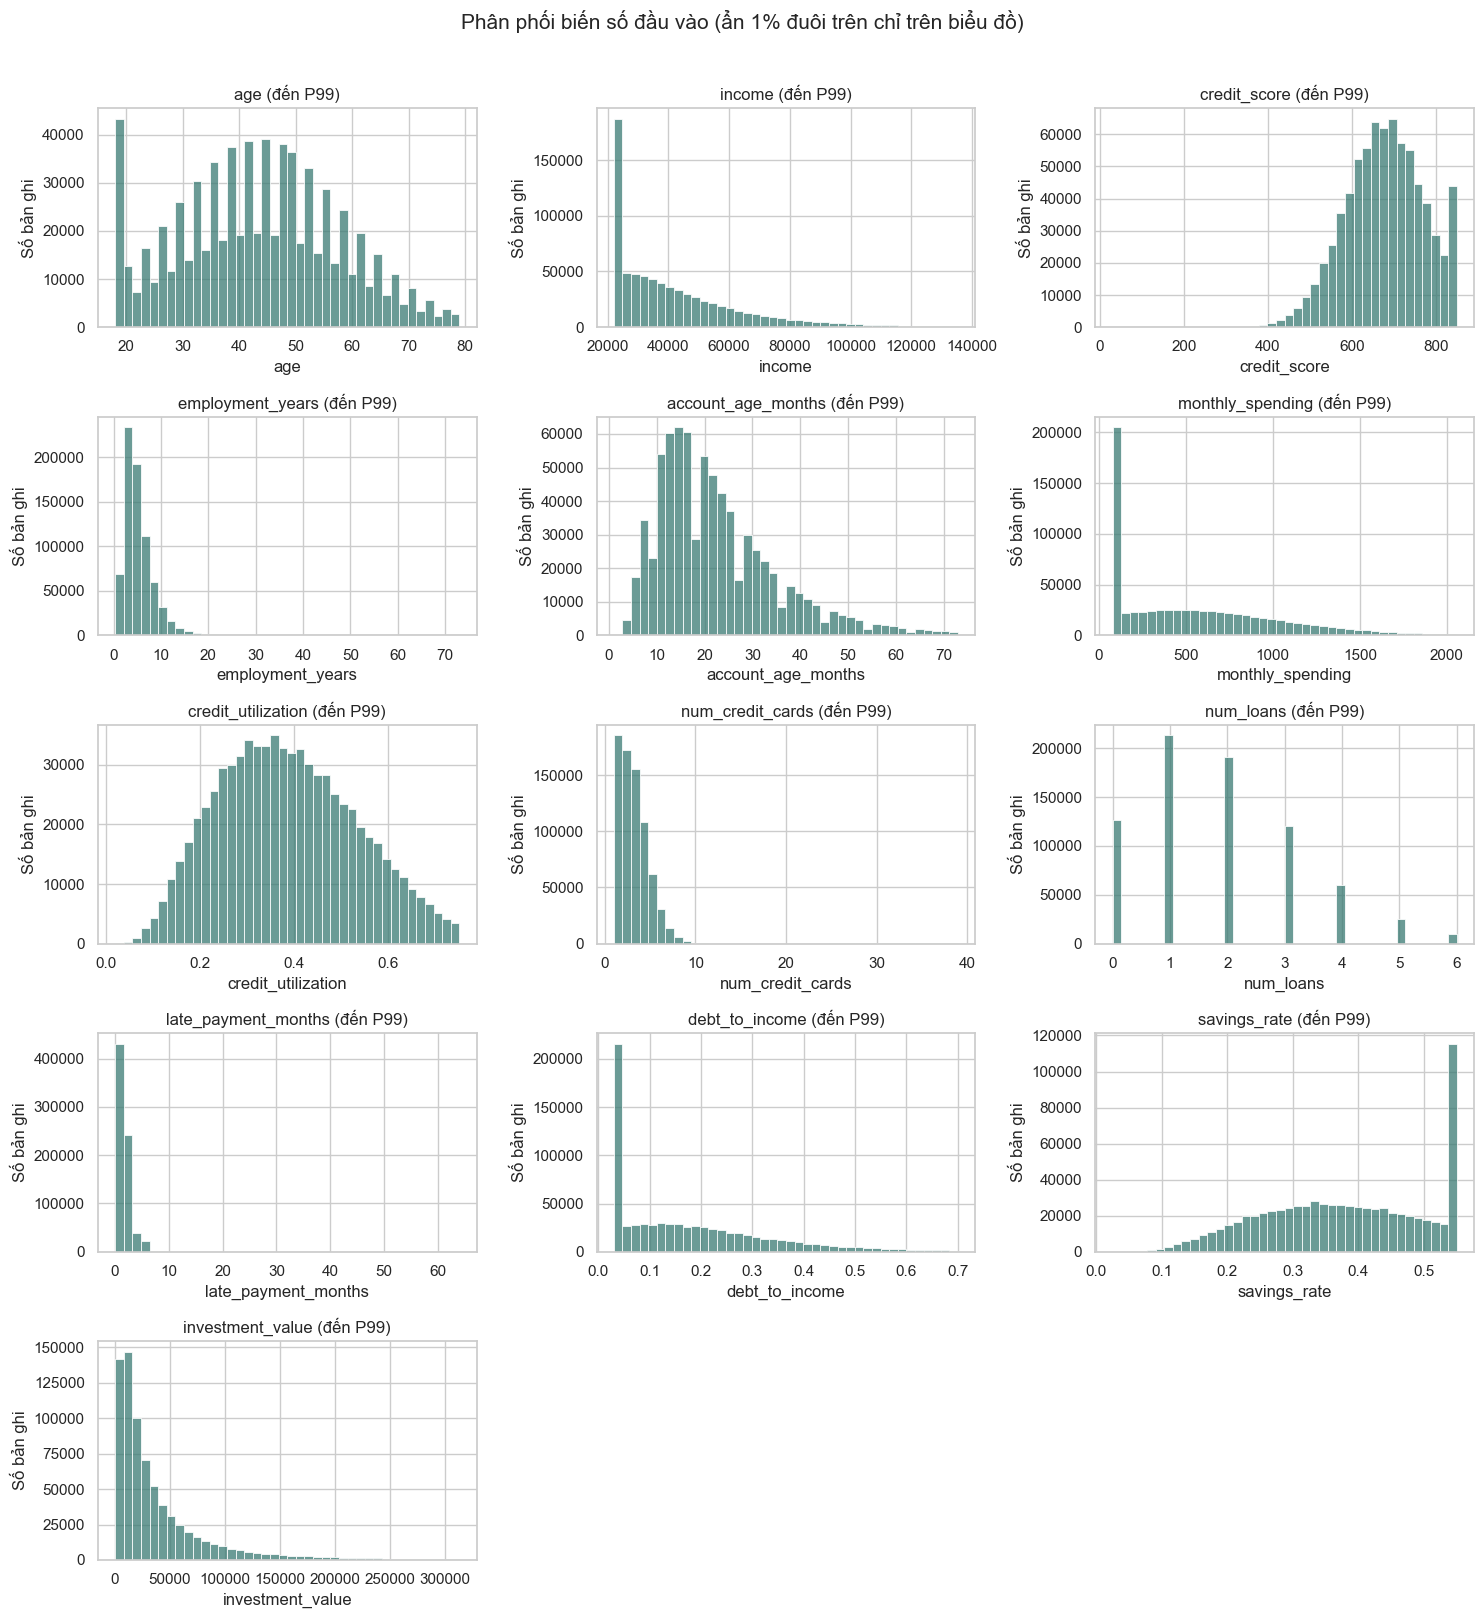

In [4]:
numeric_columns = df.select_dtypes(include=np.number).columns.tolist()
numeric_features = [
    column for column in numeric_columns
    if column not in {classification_target, regression_target}
]
display(df[numeric_features].describe().T)

plot_columns = numeric_features
column_count = 3
row_count = int(np.ceil(len(plot_columns) / column_count))
fig, axes = plt.subplots(row_count, column_count, figsize=(15, 3.2 * row_count))
axes = np.asarray(axes).reshape(-1)

for ax, column in zip(axes, plot_columns):
    values = df[column].dropna()
    upper_bound = values.quantile(0.99)
    visible_values = values[values <= upper_bound]
    sns.histplot(x=visible_values, bins=40, ax=ax, color="#397a73")
    ax.set_title(f"{column} (đến P99)")
    ax.set_xlabel(column)
    ax.set_ylabel("Số bản ghi")

for ax in axes[len(plot_columns):]:
    ax.remove()

fig.suptitle("Phân phối biến số đầu vào (ẩn 1% đuôi trên chỉ trên biểu đồ)", y=1.01, fontsize=15)
plt.tight_layout()
plt.show()

## 4. Các biến phân loại

Xem số lượng và tỷ lệ của từng nhóm giá trị để nhận biết nhóm phổ biến, nhóm hiếm hoặc cách ghi nhãn chưa thống nhất.

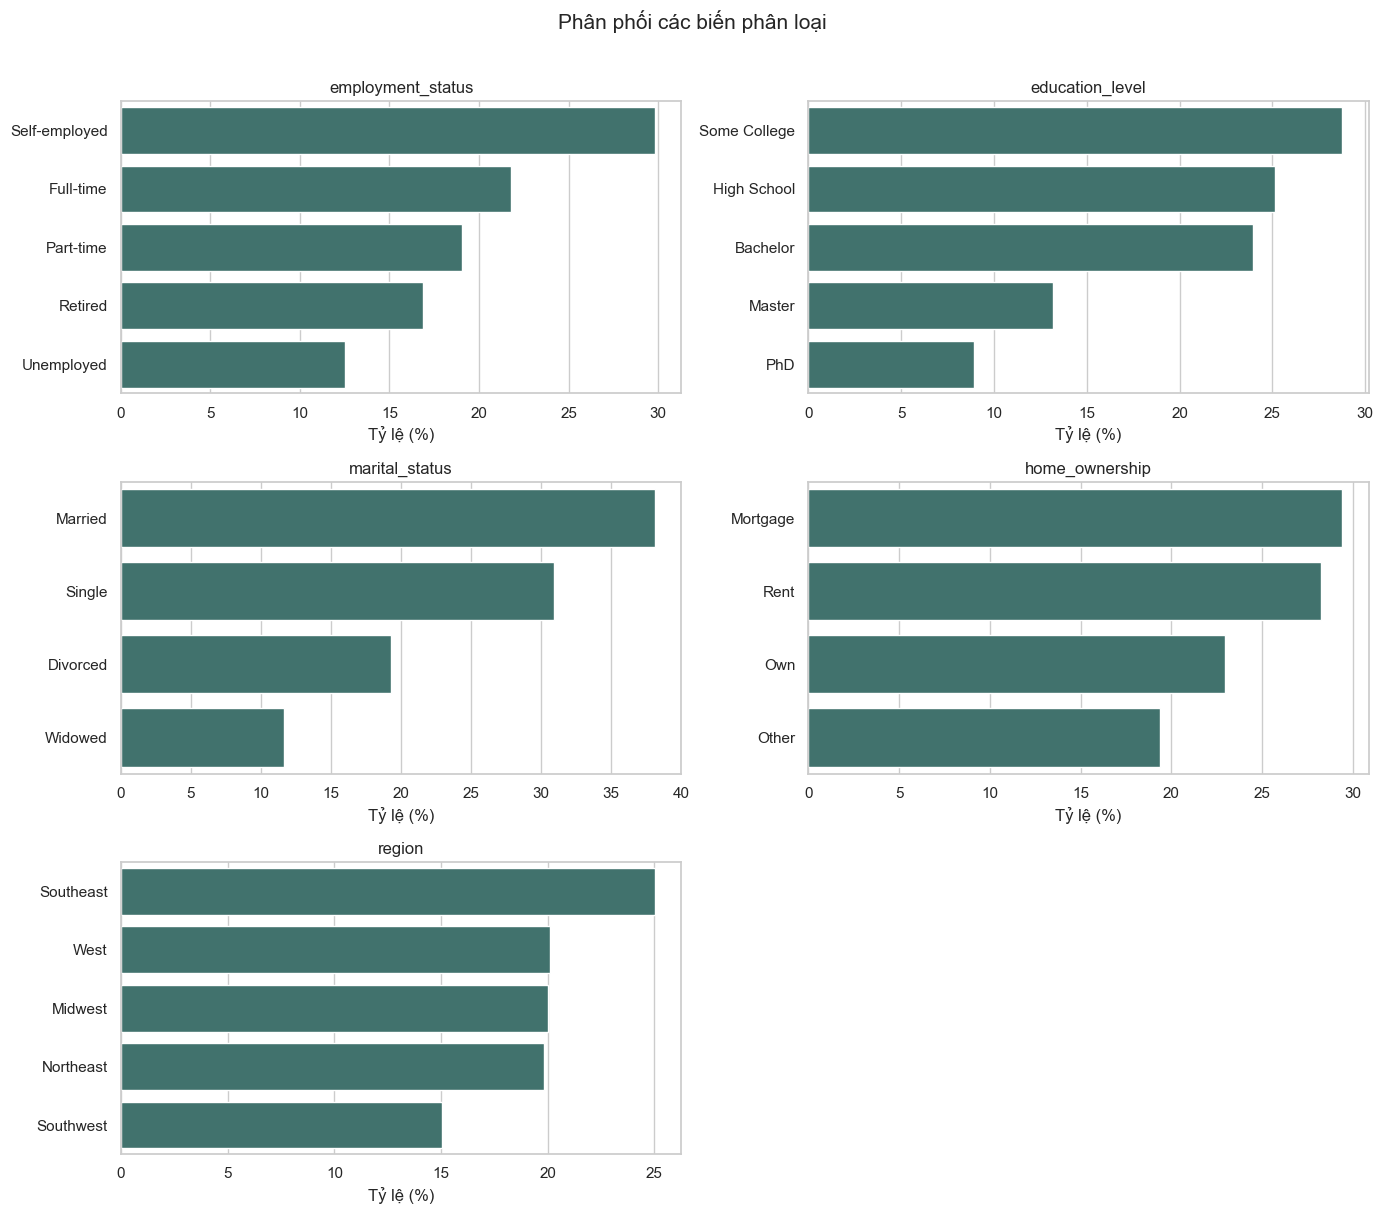

In [6]:
date_columns = ["account_creation_date", "last_transaction_date"]
categorical_columns = [
    column for column in df.select_dtypes(include=["object", "category"]).columns
    if column not in {"customer_id", *date_columns}
]

column_count = 2
row_count = int(np.ceil(len(categorical_columns) / column_count))
fig, axes = plt.subplots(row_count, column_count, figsize=(14, 4 * row_count))
axes = np.asarray(axes).reshape(-1)

for ax, column in zip(axes, categorical_columns):
    value_counts = df[column].fillna("(Thiếu)").value_counts(normalize=True).mul(100)
    sns.barplot(x=value_counts.values, y=value_counts.index, ax=ax, color="#397a73")
    ax.set_title(column)
    ax.set_xlabel("Tỷ lệ (%)")
    ax.set_ylabel("")

for ax in axes[len(categorical_columns):]:
    ax.remove()

fig.suptitle("Phân phối các biến phân loại", y=1.01, fontsize=15)
plt.tight_layout()
plt.show()

## 5. Các biến mục tiêu

`credit_risk` là biến phân loại 4 mức theo từ điển; `fraud_risk_score` là biến số liên tục. Kiểm tra tỷ lệ lớp và thống kê cơ bản để lưu ý mất cân bằng lớp hoặc giá trị mục tiêu bất thường trước khi chọn cách đánh giá mô hình.

,count,percent
credit_risk,,
0,380490,50.73%
1,174426,23.26%
2,134274,17.90%
3,60810,8.11%


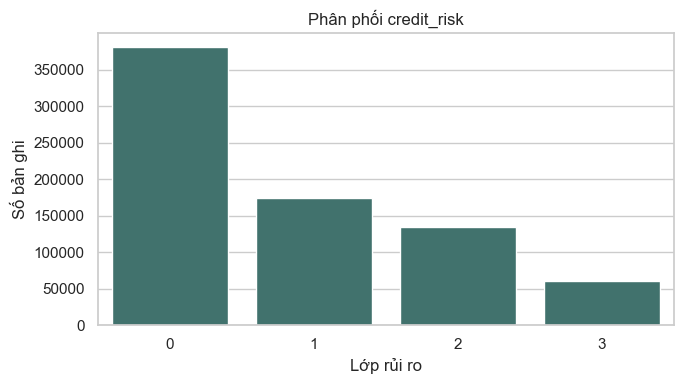

,value
count,"750,000.000"
mean,0.475
std,0.160
min,0.116
25%,0.362
50%,0.447
75%,0.556
max,2.281


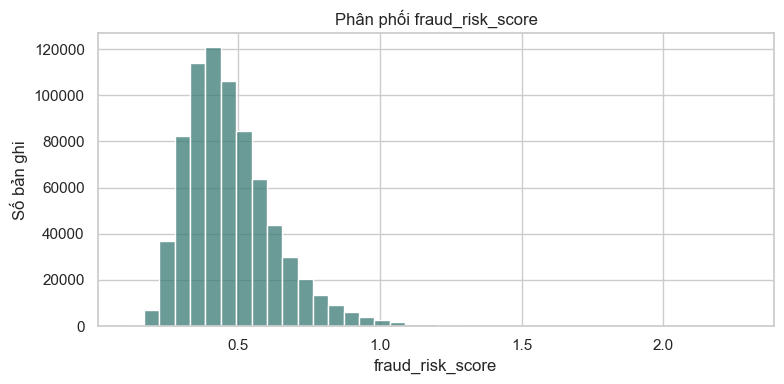

In [7]:
if classification_target in df.columns:
    class_counts = df[classification_target].value_counts(dropna=False).sort_index()
    class_summary = pd.DataFrame({
        "count": class_counts,
        "percent": class_counts.div(len(df)).mul(100),
    })
    display(class_summary.style.format({"percent": "{:.2f}%"}))

    fig, ax = plt.subplots(figsize=(7, 4))
    sns.barplot(x=class_summary.index.astype(str), y=class_summary["count"], ax=ax, color="#397a73")
    ax.set(title=f"Phân phối {classification_target}", xlabel="Lớp rủi ro", ylabel="Số bản ghi")
    plt.tight_layout()
    plt.show()
else:
    print(f"Không tìm thấy biến mục tiêu phân loại: {classification_target}")

if regression_target in df.columns:
    display(df[regression_target].describe().to_frame("value"))
    fig, ax = plt.subplots(figsize=(8, 4))
    sns.histplot(data=df, x=regression_target, bins=40, ax=ax, color="#397a73")
    ax.set(title=f"Phân phối {regression_target}", xlabel=regression_target, ylabel="Số bản ghi")
    plt.tight_layout()
    plt.show()
else:
    print(f"Không tìm thấy biến mục tiêu hồi quy: {regression_target}")

## 6. Các mốc thời gian

Chuyển đổi hai cột ngày sang datetime để xem khoảng thời gian quan sát, số ngày không đọc được và các bản ghi có giao dịch cuối trước ngày mở tài khoản.

In [8]:
available_date_columns = [column for column in date_columns if column in df.columns]
parsed_dates = df[available_date_columns].apply(pd.to_datetime, errors="coerce")

date_summary = pd.DataFrame({
    "min_date": parsed_dates.min(),
    "max_date": parsed_dates.max(),
    "unparsed_count": parsed_dates.isna().sum(),
})
display(date_summary)

if {"account_creation_date", "last_transaction_date"}.issubset(parsed_dates.columns):
    reversed_date_count = int(
        (parsed_dates["last_transaction_date"] < parsed_dates["account_creation_date"]).sum()
    )
    print("Giao dịch cuối trước ngày mở tài khoản:", f"{reversed_date_count:,}")

,min_date,max_date,unparsed_count
account_creation_date,2019-01-01,2024-06-29,0
last_transaction_date,2024-07-10,2024-12-31,0


Giao dịch cuối trước ngày mở tài khoản: 0


## 7. Ghi nhận ban đầu

- Có 6 cột thiếu dữ liệu; tỷ lệ thiếu quan sát được nằm trong khoảng 0,07%–0,77%. Không có dòng trùng hoàn toàn hoặc `customer_id` trùng.
- `credit_risk` chưa cân bằng lớp: lớp 0 chiếm khoảng 50,73%, lớp 3 khoảng 8,11%.
- Có đuôi giá trị lớn ở một số biến tài chính và giá trị cực trị cần xác minh ở `credit_score`, `employment_years`, `monthly_spending` và `fraud_risk_score`. Các giá trị này vẫn được giữ nguyên.
- Các cột ngày chuyển đổi thành công; không phát hiện ngày giao dịch cuối trước ngày tạo tài khoản.

Đây là các quan sát ban đầu, không phải kết luận về tính hợp lệ nghiệp vụ. Hãy dùng notebook kiểm tra chất lượng dữ liệu để xác minh miền giá trị, quy tắc liên cột và cơ chế thiếu trước khi làm sạch hoặc huấn luyện.